# Lab 7 — Go-to-goal along the digits **7 0** (student ID …70)

The robot drives a list of waypoints with a go-to-goal controller, first in the TRIK Studio simulator and then on the real robot. Both runs only **log** the wheel angles; this notebook reconstructs the trajectories offline and compares them with the ideal trajectory.

**Waypoints (m).** Only straight lines and 90° corners; each digit is 0.5 m wide and 1 m tall. The robot starts at the top-left corner of the 7, facing +x.

| # | segment | from → to |
|---|---------|-----------|
| 1 | 7, top bar | (0, 0) → (0.5, 0) |
| 2 | 7, vertical | (0.5, 0) → (0.5, −1.0) |
| 3 | gap + 0 bottom | (0.5, −1.0) → (1.4, −1.0) |
| 4 | 0, right | (1.4, −1.0) → (1.4, 0) |
| 5 | 0, top | (1.4, 0) → (0.9, 0) |
| 6 | 0, left | (0.9, 0) → (0.9, −1.0) |

**Controller** — the template's controller, unchanged, same gains in both runs:
`u = 50·err`, `mov = 50·distance·cos(err)`, `M3 (left) = mov − u`, `M4 (right) = mov + u`, where `err` is the courseAngle (wrapped to (−π, π] by the IF block). The robot drives while turning (no turn in place). Acceptance radius ε = threshold = 0.05 m. Coordinates are in metres; `distance` is reported in cm as the lab asks. Speeds are motor power in %, so `B/2` is absorbed into the gain.

**Upload** `odometry_data_sim.txt` and `odometry_data_real.txt` to the Colab file panel (or the same folder as this notebook) before running.

In [1]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- waypoints (m) — must match x_target, y_target in the programs ----------
X_ref = np.array([0, 0.5,  0.5,  1.4, 1.4, 0.9,  0.9])
Y_ref = np.array([0, 0.0, -1.0, -1.0, 0.0, 0.0, -1.0])

# ---------- robot geometry (m) — put YOUR measured values here ----------
r_sim,  B_sim  = 0.042, 0.194     # TRIK Studio 2D model (same as go_to_goal_sim.qrs)
r_real, B_real = 0.0375, 0.194     # real robot: measured wheel radius and base
course0 = 0.0                    # initial course, rad (robot faces +x at the start)

EPS = 0.05                       # acceptance radius used in the programs, m
CORNER_ZONE = 0.15               # m; samples this close to a segment end count as "corner"

FILES = {"sim": "odometry_data_sim.txt", "real": "odometry_data_real.txt"}

## Loading the logs
Expected format: `theta_l,theta_r,time` per line, no header (rad, rad, ms). The loader is tolerant: it pulls every number out of the file in order and groups them in threes, so a header line, trailing commas, `;` separators, or one value per line (TRIK Studio's *Write to file* block on some versions) all still work. The file is printed so you can see what it actually contains.

In [2]:
NUM = re.compile(r'[-+]?(?:\d+\.\d*|\.\d+|\d+)(?:[eE][-+]?\d+)?')

def load_log(path):
    txt = open(path, encoding="utf-8", errors="ignore").read()
    lines = [l for l in txt.splitlines() if l.strip()]
    print(f"{path}: {len(lines)} non-empty lines; first 3:", lines[:3])
    vals = []
    for l in lines:
        if re.search(r'[A-Za-z]{3,}', l):     # header such as theta_l,theta_r,time
            continue
        vals += [float(v) for v in NUM.findall(l)]
    vals = np.array(vals)
    if len(vals) % 3:
        print(f"  warning: {len(vals)} numbers is not a multiple of 3, dropping the tail")
        vals = vals[: len(vals) // 3 * 3]
    d = vals.reshape(-1, 3)
    thl, thr, t = d[:, 0], d[:, 1], d[:, 2]
    # keep samples in time order, drop exact duplicates
    keep = np.r_[True, np.diff(t) > 0] | np.r_[True, (np.diff(thl) != 0) | (np.diff(thr) != 0)]
    return thl[keep], thr[keep], (t[keep] - t[keep][0]) / 1000.0   # time in s

DEMO = False
logs = {}
for k, f in FILES.items():
    if os.path.exists(f):
        logs[k] = load_log(f)
if len(logs) < 2:
    DEMO = True
    print("\n*** One or both logs are missing — running on DEMO data from demo/demo_make_logs.py. "
          "Upload your real logs and re-run before submitting. ***")
    for k in FILES:
        if k not in logs:
            logs[k] = load_log(os.path.join("demo", "demo_odometry_data_" + k + ".txt"))

odometry_data_sim.txt: 8343 non-empty lines; first 3: ['0,0,0', '0,0,10', '0.017453292519943295,0.017453292519943295,20']
odometry_data_real.txt: 544 non-empty lines; first 3: ['0,0,20', '0.017453292519943295,0.017453292519943295,84', '0.08726646259971647,0.10471975511965977,153']


## Step 1 — Reconstruct the trajectory
Start at the first waypoint with `course_0`, then for every sample:
`path = (θr+θl)·r/2`, `course = course_0 + (θr−θl)·r/B`, `x += Δpath·cos(course)`, `y += Δpath·sin(course)`.

In [3]:
def reconstruct(thl, thr, r, B):
    path = (thr + thl) * r / 2
    course = course0 + (thr - thl) * r / B
    x = np.empty_like(path); y = np.empty_like(path)
    x[0], y[0] = X_ref[0], Y_ref[0]
    for k in range(1, len(path)):
        dp = path[k] - path[k - 1]
        x[k] = x[k - 1] + dp * np.cos(course[k])
        y[k] = y[k - 1] + dp * np.sin(course[k])
    return x, y, course

runs = {}
for k, (r, B) in {"sim": (r_sim, B_sim), "real": (r_real, B_real)}.items():
    thl, thr, t = logs[k]
    x, y, course = reconstruct(thl, thr, r, B)
    runs[k] = dict(t=t, x=x, y=y, course=course)
    print(f"{k}: {len(t)} samples, {t[-1]:.1f} s, end at ({x[-1]:.3f}, {y[-1]:.3f}) m")

sim: 8343 samples, 83.4 s, end at (0.898, -0.950) m
real: 544 samples, 26.5 s, end at (0.895, -0.952) m


## Steps 2–4 — Ideal segments, segment assignment, `distance` and `courseAngle`
Segment *i* runs from waypoint *i−1* to *i* with `course_ref[i] = atan2(ΔY, ΔX)`. Samples are assigned in order: each sample may stay on the current segment or move to the next one, whichever is nearer — so the last segment, which ends on segment 3, cannot pull samples back to an earlier segment.

`distance = −(x−X_ref[i−1])·sin(course_ref[i]) + (y−Y_ref[i−1])·cos(course_ref[i])` (computed in m, shown in cm, + = left of the segment), `courseAngle = course_ref[i] − course`, wrapped to [−180°, 180°].

In [4]:
nseg = len(X_ref) - 1
course_ref = np.r_[np.nan, np.arctan2(np.diff(Y_ref), np.diff(X_ref))]   # index 1..nseg

def dist_to_segment(px, py, i):
    ax, ay, bx, by = X_ref[i-1], Y_ref[i-1], X_ref[i], Y_ref[i]
    vx, vy = bx - ax, by - ay
    s = np.clip(((px-ax)*vx + (py-ay)*vy) / (vx*vx + vy*vy), 0, 1)
    return np.hypot(px - (ax + s*vx), py - (ay + s*vy))

def wrap_deg(a):
    return (a + 180) % 360 - 180

def analyse(run):
    x, y, course = run["x"], run["y"], run["course"]
    seg = np.empty(len(x), dtype=int)
    i = 1
    for k in range(len(x)):
        if i < nseg and dist_to_segment(x[k], y[k], i + 1) < dist_to_segment(x[k], y[k], i):
            i += 1
        seg[k] = i
    a = course_ref[seg]
    d = 100 * (-(x - X_ref[seg-1]) * np.sin(a) + (y - Y_ref[seg-1]) * np.cos(a))   # cm
    ca = wrap_deg(np.degrees(a - course))
    # straight-part mask: away from both ends of the assigned segment
    near_start = np.hypot(x - X_ref[seg-1], y - Y_ref[seg-1]) < CORNER_ZONE
    near_end   = np.hypot(x - X_ref[seg],   y - Y_ref[seg])   < CORNER_ZONE
    run.update(seg=seg, distance=d, courseAngle=ca, straight=~(near_start | near_end))
    return run

for k in runs:
    analyse(runs[k])

## Step 5 — Plots

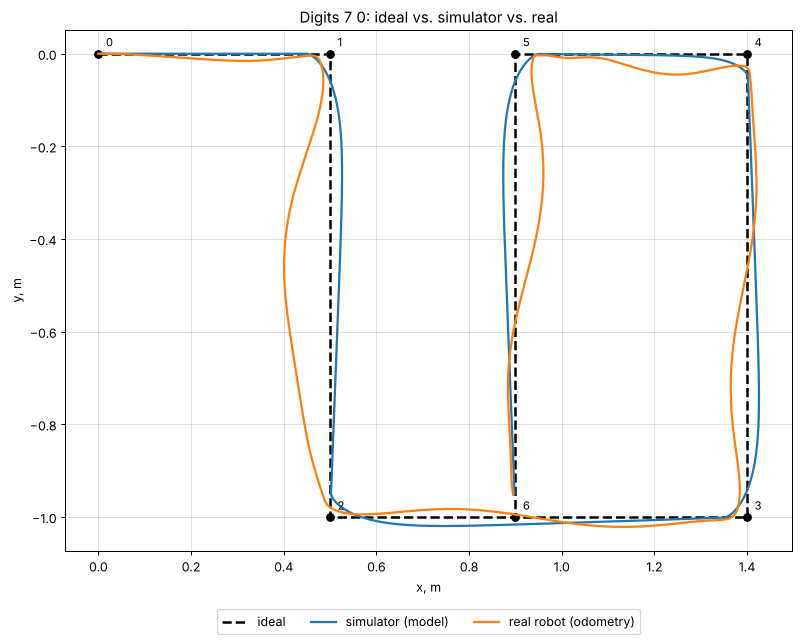

In [5]:
tag = "  (DEMO DATA)" if DEMO else ""
fig, ax = plt.subplots(figsize=(9, 7))
ax.plot(X_ref, Y_ref, "k--", lw=2, label="ideal")
ax.plot(X_ref, Y_ref, "ko", ms=6)
for j, (px, py) in enumerate(zip(X_ref, Y_ref)):
    ax.annotate(str(j), (px, py), textcoords="offset points", xytext=(6, 6), fontsize=9)
ax.plot(runs["sim"]["x"],  runs["sim"]["y"],  "-", color="tab:blue",   lw=1.8, label="simulator (model)")
ax.plot(runs["real"]["x"], runs["real"]["y"], "-", color="tab:orange", lw=1.8, label="real robot (odometry)")
ax.set_aspect("equal"); ax.grid(True, alpha=.4)
ax.set_xlabel("x, m"); ax.set_ylabel("y, m")
ax.set_title("Digits 7 0: ideal vs. simulator vs. real" + tag)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
plt.tight_layout()
plt.show()

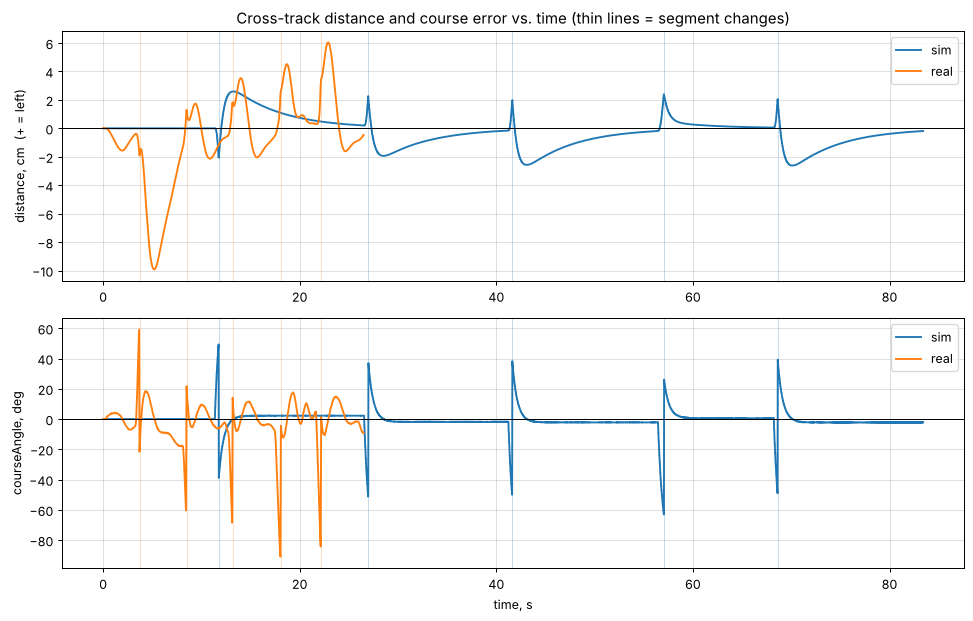

In [6]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 7), sharex=False)
for k, c in [("sim", "tab:blue"), ("real", "tab:orange")]:
    R = runs[k]
    a1.plot(R["t"], R["distance"], color=c, label=k)
    a2.plot(R["t"], R["courseAngle"], color=c, label=k)
    # mark the moments the run switches segment
    for tk in R["t"][np.r_[False, np.diff(R["seg"]) != 0]]:
        a1.axvline(tk, color=c, alpha=.25, lw=.8); a2.axvline(tk, color=c, alpha=.25, lw=.8)
a1.axhline(0, color="k", lw=.8); a2.axhline(0, color="k", lw=.8)
a1.set_ylabel("distance, cm  (+ = left)"); a2.set_ylabel("courseAngle, deg")
a2.set_xlabel("time, s"); a1.grid(alpha=.4); a2.grid(alpha=.4); a1.legend(); a2.legend()
a1.set_title("Cross-track distance and course error vs. time (thin lines = segment changes)" + tag)
plt.tight_layout(); plt.show()

### Waypoint miss — smallest distance between each reconstructed trajectory and each waypoint

In [7]:
rows = []
for j in range(len(X_ref)):
    row = {"waypoint": j, "X_ref, m": X_ref[j], "Y_ref, m": Y_ref[j]}
    for k in runs:
        row[f"miss {k}, cm"] = 100 * np.min(np.hypot(runs[k]["x"] - X_ref[j], runs[k]["y"] - Y_ref[j]))
    rows.append(row)
miss = pd.DataFrame(rows).set_index("waypoint")
miss.round(2)

,"X_ref, m","Y_ref, m","miss sim, cm","miss real, cm"
waypoint,,,,
0,0.0,0.0,0.00,0.00
1,0.5,0.0,3.00,2.72
2,0.5,-1.0,3.20,1.80
3,1.4,-1.0,2.89,2.59
4,1.4,0.0,3.28,2.76
5,0.9,0.0,3.00,3.97
6,0.9,-1.0,1.62,0.55


### Summary per run

In [8]:
def summary(R):
    d, ca, st = R["distance"], R["courseAngle"], R["straight"]
    return {
        "max |distance|, cm": np.max(np.abs(d)),
        "RMS distance, cm": np.sqrt(np.mean(d**2)),
        "mean |courseAngle|, deg (all)": np.mean(np.abs(ca)),
        "mean |courseAngle|, deg (straights)": np.mean(np.abs(ca[st])) if st.any() else np.nan,
        "final error to last waypoint, cm": 100 * np.hypot(R["x"][-1] - X_ref[-1], R["y"][-1] - Y_ref[-1]),
        "run time, s": R["t"][-1],
    }
summ = pd.DataFrame({k: summary(runs[k]) for k in runs})
summ.round(2)

,sim,real
"max |distance|, cm",2.62,9.93
"RMS distance, cm",1.06,3.20
"mean |courseAngle|, deg (all)",3.17,9.46
"mean |courseAngle|, deg (straights)",1.70,6.81
"final error to last waypoint, cm",4.97,4.83
"run time, s",83.42,26.51


In [9]:
# per-segment breakdown: where do the errors grow?
names = ["7 top", "7 vertical", "gap + 0 bottom", "0 right", "0 top", "0 left"]
rows = []
for i in range(1, nseg + 1):
    row = {"segment": f"{i}: {names[i-1]}"}
    for k in runs:
        m = (runs[k]["seg"] == i) & runs[k]["straight"]
        row[f"{k} max|d|, cm"] = np.max(np.abs(runs[k]["distance"][m])) if m.any() else np.nan
        row[f"{k} mean|ca|, deg"] = np.mean(np.abs(runs[k]["courseAngle"][m])) if m.any() else np.nan
    rows.append(row)
pd.DataFrame(rows).set_index("segment").round(2)

,"sim max|d|, cm","sim mean|ca|, deg","real max|d|, cm","real mean|ca|, deg"
segment,,,,
1: 7 top,0.00,0.00,1.57,2.79
2: 7 vertical,2.59,2.11,9.93,9.59
3: gap + 0 bottom,1.94,1.77,2.13,4.93
4: 0 right,2.57,2.08,3.53,5.63
5: 0 top,0.41,0.72,4.51,10.02
6: 0 left,2.62,2.14,6.04,7.06


## Measured end point (real robot)
Measure the robot's final position with a tape measure in the same frame (origin = start point, x = initial heading, y = to the left) and enter it below.

In [10]:
x_meas, y_meas = np.nan, np.nan        # <-- your tape-measure values, m

xo, yo = runs["real"]["x"][-1], runs["real"]["y"][-1]
print(f"last waypoint           : ({X_ref[-1]:.3f}, {Y_ref[-1]:.3f}) m")
print(f"odometry end (real log) : ({xo:.3f}, {yo:.3f}) m")
print(f"measured end            : ({x_meas:.3f}, {y_meas:.3f}) m")
print(f"measured vs waypoint    : {100*np.hypot(x_meas - X_ref[-1], y_meas - Y_ref[-1]):.1f} cm   (true control+localization error)")
print(f"measured vs odometry    : {100*np.hypot(x_meas - xo, y_meas - yo):.1f} cm   (localization / odometry drift)")
print(f"odometry vs waypoint    : {100*np.hypot(xo - X_ref[-1], yo - Y_ref[-1]):.1f} cm   (what the controller 'thinks')")

last waypoint           : (0.900, -1.000) m
odometry end (real log) : (0.895, -0.952) m
measured end            : (nan, nan) m
measured vs waypoint    : nan cm   (true control+localization error)
measured vs odometry    : nan cm   (localization / odometry drift)
odometry vs waypoint    : 4.8 cm   (what the controller 'thinks')


## Discussion (3–6 sentences)

*Fill in after running on your logs — use the per-segment table, the waypoint-miss table and the end-point check.*

1. **Where do `distance` and `courseAngle` grow; which corners were cut or overshot, and why?**
   The courseAngle peaks at every corner as expected; all corners are 90° turns (waypoints 1, 2, 3, 4, 5). With `mov = 50·distance·cos(err)` the robot slows near each corner, turns while still driving and switches to the next waypoint at ε = 5 cm, so the 90° corners get rounded; the rounding at waypoints __ comes from ε, and any oscillation / wide arcs on segment __ come from the turn gain 50 being too high / too low. _(edit with your numbers)_

2. **Is the remaining real-vs-model gap a control or a localization problem?**
   If the odometry end point is within ~ε of the last waypoint but the tape-measured end point is far from both, the controller did its job and the gap is **localization** (wheel radius/base errors, slip during the in-place turns). If the real odometry itself shows large `distance` on the straights compared with the simulator, it is a **control** problem (motor asymmetry, dead zone, gains). _(edit with your measured end point)_